# Física I — Cinemática e Leis de Newton

### Material de estudo visual — Engenharia Naval, Poli-USP

Este notebook é um guia de **revisão** para a primeira parte do curso de Física I. A ideia não é resolver exercícios, mas sim **ver** os conceitos: cada fórmula importante vem acompanhada de um gráfico, uma animação ou um diagrama que mostra o que ela significa de verdade.

Use-o como um "livro vivo": rode as células, mude os parâmetros (velocidades iniciais, ângulos, coeficientes de atrito) e observe como as curvas e animações mudam. A melhor forma de internalizar cinemática e as Leis de Newton é construir intuição visual para o que as equações estão dizendo.

## Sumário

1. [Movimento em uma dimensão](#sec1)
    - [1.1 Posição, velocidade e aceleração](#sec1-1)
    - [1.2 Gráficos x(t), v(t), a(t)](#sec1-2)
    - [1.3 MRUV e a animação da partícula](#sec1-3)
    - [1.4 Área sob v(t) = deslocamento](#sec1-4)
2. [Movimento em duas e três dimensões](#sec2)
    - [2.1 Vetores: soma, componentes, produtos](#sec2-1)
    - [2.2 Lançamento de projéteis](#sec2-2)
    - [2.3 Movimento circular uniforme](#sec2-3)
3. [Leis de Newton](#sec3)
    - [3.1 As três leis](#sec3-1)
    - [3.2 Ação e reação](#sec3-2)
    - [3.3 Atrito estático e cinético](#sec3-3)
    - [3.4 Dinâmica do movimento circular](#sec3-4)


## Configuração inicial

Rode esta célula primeiro. Ela importa tudo que vamos usar e define um estilo visual consistente (grid leve, paleta de cores agradável) para todos os gráficos do notebook.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import FancyArrowPatch, Circle, Arc
from IPython.display import HTML
import sympy as sp

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "font.size": 11,
    "lines.linewidth": 2.2,
    "axes.prop_cycle": plt.cycler(color=[
        "#1f77b4", "#d62728", "#2ca02c", "#9467bd",
        "#ff7f0e", "#17becf", "#8c564b", "#e377c2",
    ]),
})

COR_DESTAQUE = "#d62728"
COR_OK = "#2ca02c"
COR_AZUL = "#1f77b4"
print("Setup concluído. Bibliotecas carregadas: numpy, matplotlib, sympy.")


Setup concluído. Bibliotecas carregadas: numpy, matplotlib, sympy.


<a id="sec1"></a>
## 1. Movimento em uma dimensão

<a id="sec1-1"></a>
### 1.1 Posição, velocidade e aceleração

Em uma dimensão, descrevemos o movimento de uma partícula por sua posição $x(t)$. A partir dela definimos:

**Velocidade média** entre dois instantes:
$$\bar v = \frac{\Delta x}{\Delta t} = \frac{x(t_2)-x(t_1)}{t_2-t_1}$$

**Velocidade instantânea**, o limite quando $\Delta t \to 0$ — ou seja, a *derivada* da posição:
$$v(t) = \frac{dx}{dt}$$

**Aceleração instantânea**, a derivada da velocidade (ou segunda derivada da posição):
$$a(t) = \frac{dv}{dt} = \frac{d^2x}{dt^2}$$

Geometricamente: $v$ é a **inclinação da reta tangente** ao gráfico $x(t)$ em cada instante, e $a$ é a inclinação da tangente ao gráfico $v(t)$.

> **Intuição física:** pense em $x(t)$ como o "mapa" da posição ao longo do tempo. Se o mapa cresce rápido, a inclinação é grande e a velocidade é alta. Se o mapa é uma reta, a velocidade é constante e a aceleração é nula. Se o mapa curva para cima, há aceleração positiva.

In [2]:
# Vamos usar sympy para calcular simbolicamente v(t) e a(t) a partir de x(t)
t_sym = sp.symbols('t', positive=True)
x_sym = 2*t_sym**3 - 9*t_sym**2 + 12*t_sym  # posição de exemplo (m), t em s

v_sym = sp.diff(x_sym, t_sym)
a_sym = sp.diff(v_sym, t_sym)

print("x(t) =", x_sym)
print("v(t) = dx/dt =", v_sym)
print("a(t) = dv/dt =", a_sym)


x(t) = 2*t**3 - 9*t**2 + 12*t
v(t) = dx/dt = 6*t**2 - 18*t + 12
a(t) = dv/dt = 12*t - 18


<a id="sec1-2"></a>
### 1.2 Gráficos x(t), v(t), a(t) empilhados

Vamos plotar as três curvas uma embaixo da outra, para a mesma escala de tempo, e destacar visualmente um instante $t^*$ onde a inclinação de $x(t)$ (reta tangente) é exatamente o valor de $v(t^*)$.

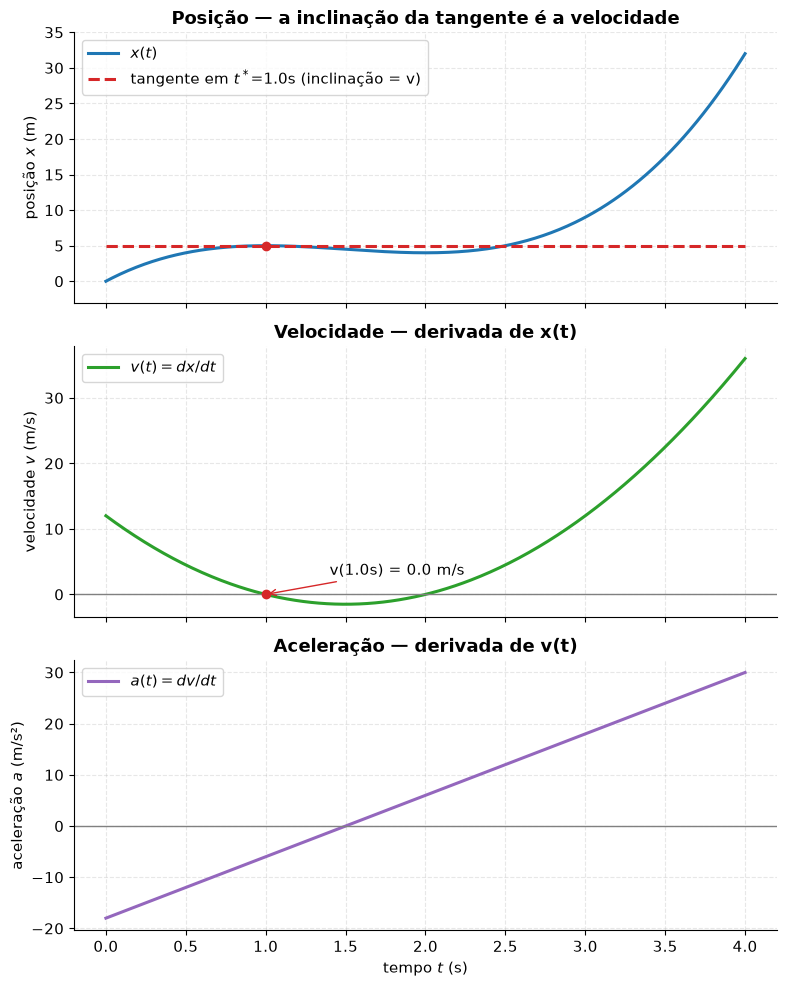

In [3]:
x_func = sp.lambdify(t_sym, x_sym, 'numpy')
v_func = sp.lambdify(t_sym, v_sym, 'numpy')
a_func = sp.lambdify(t_sym, a_sym, 'numpy')

ts = np.linspace(0, 4, 400)
xs, vs, as_ = x_func(ts), v_func(ts), a_func(ts)

t_star = 1.0
x_star, v_star = x_func(t_star), v_func(t_star)

fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

# x(t) com reta tangente em t*
axs[0].plot(ts, xs, color=COR_AZUL, label="$x(t)$")
tang = x_star + v_star * (ts - t_star)
axs[0].plot(ts, tang, "--", color=COR_DESTAQUE, label=f"tangente em $t^*$={t_star}s (inclinação = v)")
axs[0].scatter([t_star], [x_star], color=COR_DESTAQUE, zorder=5)
axs[0].set_ylim(xs.min()-3, xs.max()+3)
axs[0].set_ylabel("posição $x$ (m)")
axs[0].set_title("Posição — a inclinação da tangente é a velocidade")
axs[0].legend(loc="upper left")

# v(t)
axs[1].plot(ts, vs, color=COR_OK, label="$v(t) = dx/dt$")
axs[1].scatter([t_star], [v_star], color=COR_DESTAQUE, zorder=5)
axs[1].axhline(0, color="gray", lw=1)
axs[1].annotate(f"v({t_star}s) = {v_star:.1f} m/s", xy=(t_star, v_star),
                 xytext=(t_star+0.4, v_star+3),
                 arrowprops=dict(arrowstyle="->", color=COR_DESTAQUE))
axs[1].set_ylabel("velocidade $v$ (m/s)")
axs[1].set_title("Velocidade — derivada de x(t)")
axs[1].legend(loc="upper left")

# a(t)
axs[2].plot(ts, as_, color="#9467bd", label="$a(t) = dv/dt$")
axs[2].axhline(0, color="gray", lw=1)
axs[2].set_ylabel("aceleração $a$ (m/s²)")
axs[2].set_xlabel("tempo $t$ (s)")
axs[2].set_title("Aceleração — derivada de v(t)")
axs[2].legend(loc="upper left")

plt.tight_layout()
plt.show()


> **Dica de prova:** quando $v(t)=0$ mas $a(t) \neq 0$, a partícula está instantaneamente parada mas *vai* mudar de direção — é um ponto de máximo ou mínimo local de $x(t)$. Observe acima que perto de $t\approx 1\,$s e $t\approx 3\,$s a curva $v(t)$ cruza o zero exatamente nos pontos onde $x(t)$ tem um pico ou vale.

<a id="sec1-3"></a>
### 1.3 MRUV — Movimento Retilíneo Uniformemente Variado

Quando a aceleração é **constante**, valem as equações clássicas (equações de Torricelli e companhia):

$$x(t) = x_0 + v_0 t + \tfrac{1}{2}at^2 \qquad\qquad v(t) = v_0 + at \qquad\qquad v^2 = v_0^2 + 2a\,\Delta x$$

Abaixo, uma animação de uma partícula em MRUV: a bolinha se move em uma reta (eixo horizontal) enquanto os gráficos de $x(t)$ e $v(t)$ são traçados em tempo real, ponto a ponto, mostrando a posição e a velocidade *naquele exato instante*.

In [4]:
# Parâmetros do MRUV
x0, v0, a0 = -8.0, 2.0, 3.0   # posição inicial, vel. inicial, aceleração (constante)
T = 3.0
n_frames = 60
t_anim = np.linspace(0, T, n_frames)
x_anim = x0 + v0*t_anim + 0.5*a0*t_anim**2
v_anim = v0 + a0*t_anim

fig, (ax_track, ax_x, ax_v) = plt.subplots(3, 1, figsize=(8, 9),
                                            gridspec_kw={"height_ratios": [1, 1.3, 1.3]})

# Trilha (eixo 1D)
ax_track.set_xlim(x_anim.min()-2, x_anim.max()+2)
ax_track.set_ylim(-1, 1)
ax_track.axhline(0, color="gray", lw=1.5)
ax_track.set_yticks([])
ax_track.set_title("Partícula em MRUV (trajetória 1D)")
ax_track.set_xlabel("posição $x$ (m)")
particula, = ax_track.plot([], [], "o", color=COR_DESTAQUE, markersize=16, zorder=5)
seta_v = ax_track.annotate("", xy=(0,0), xytext=(0,0),
                            arrowprops=dict(arrowstyle="->", color=COR_AZUL, lw=2))

ax_x.set_xlim(0, T); ax_x.set_ylim(x_anim.min()-2, x_anim.max()+2)
ax_x.set_ylabel("$x$ (m)"); ax_x.set_title("$x(t) = x_0 + v_0 t + \\frac{1}{2}at^2$")
linha_x, = ax_x.plot([], [], color=COR_AZUL)

ax_v.set_xlim(0, T); ax_v.set_ylim(v_anim.min()-1, v_anim.max()+1)
ax_v.set_ylabel("$v$ (m/s)"); ax_v.set_xlabel("tempo $t$ (s)")
ax_v.set_title("$v(t) = v_0 + at$")
linha_v, = ax_v.plot([], [], color=COR_OK)

plt.tight_layout()

def init():
    particula.set_data([], [])
    linha_x.set_data([], [])
    linha_v.set_data([], [])
    return particula, linha_x, linha_v

def update(i):
    particula.set_data([x_anim[i]], [0])
    vx = v_anim[i]
    comp = 0.6 * np.sign(vx) * min(abs(vx), 3)
    seta_v.xy = (x_anim[i] + comp, 0.3)
    seta_v.set_position((x_anim[i], 0.3))
    linha_x.set_data(t_anim[:i+1], x_anim[:i+1])
    linha_v.set_data(t_anim[:i+1], v_anim[:i+1])
    return particula, linha_x, linha_v

anim = animation.FuncAnimation(fig, update, frames=n_frames, init_func=init,
                                interval=60, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())


<a id="sec1-4"></a>
### 1.4 Área sob v(t) = deslocamento

Uma propriedade geométrica muito usada: a **área sob a curva** $v(t)$ entre dois instantes é igual ao deslocamento $\Delta x$ nesse intervalo, pois

$$\Delta x = \int_{t_1}^{t_2} v(t)\,dt.$$

Isso vale mesmo quando $v(t)$ não é constante — inclusive quando a velocidade muda de sinal (aí a área "negativa" representa deslocamento no sentido contrário).

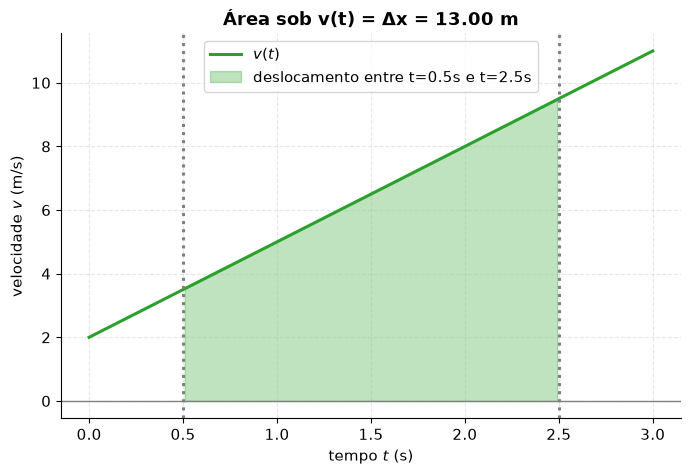

In [5]:
t1, t2 = 0.5, 2.5
fig, ax = plt.subplots()
ax.plot(t_anim, v_anim, color=COR_OK, label="$v(t)$")
mask = (t_anim >= t1) & (t_anim <= t2)
ax.fill_between(t_anim[mask], v_anim[mask], color=COR_OK, alpha=0.3,
                 label=f"deslocamento entre t={t1}s e t={t2}s")
ax.axvline(t1, color="gray", ls=":")
ax.axvline(t2, color="gray", ls=":")
ax.axhline(0, color="gray", lw=1)
delta_x = (x0 + v0*t2 + 0.5*a0*t2**2) - (x0 + v0*t1 + 0.5*a0*t1**2)
ax.set_title(f"Área sob v(t) = Δx = {delta_x:.2f} m")
ax.set_xlabel("tempo $t$ (s)")
ax.set_ylabel("velocidade $v$ (m/s)")
ax.legend()
plt.show()


> **Intuição física:** pensar em "área = deslocamento" é útil quando o gráfico de $v(t)$ é complicado (não constante, não linear) e as fórmulas do MRUV não se aplicam diretamente — basta calcular (ou estimar) a área sob a curva.

<a id="sec2"></a>
## 2. Movimento em duas e três dimensões

<a id="sec2-1"></a>
### 2.1 Vetores: soma, componentes e produtos

Em 2D/3D, posição, velocidade e aceleração são **vetores**: $\vec r$, $\vec v = d\vec r/dt$, $\vec a = d\vec v/dt$.

**Soma vetorial (regra do paralelogramo):** para somar $\vec A + \vec B$, colocamos a cauda de $\vec B$ na ponta de $\vec A$; o vetor soma vai da cauda de $\vec A$ até a ponta de $\vec B$.

**Componentes:** todo vetor no plano pode ser escrito como $\vec A = A_x\,\hat\imath + A_y\,\hat\jmath$, com $A_x = |\vec A|\cos\theta$ e $A_y = |\vec A|\sin\theta$.

**Produto escalar** (resulta em um número, mede "quanto dois vetores apontam na mesma direção"):
$$\vec A \cdot \vec B = A_xB_x + A_yB_y = |\vec A||\vec B|\cos\theta$$

**Produto vetorial** (resulta em um vetor perpendicular ao plano de $\vec A$ e $\vec B$, usado por exemplo em torque e momento angular):
$$|\vec A \times \vec B| = |\vec A||\vec B|\sin\theta$$

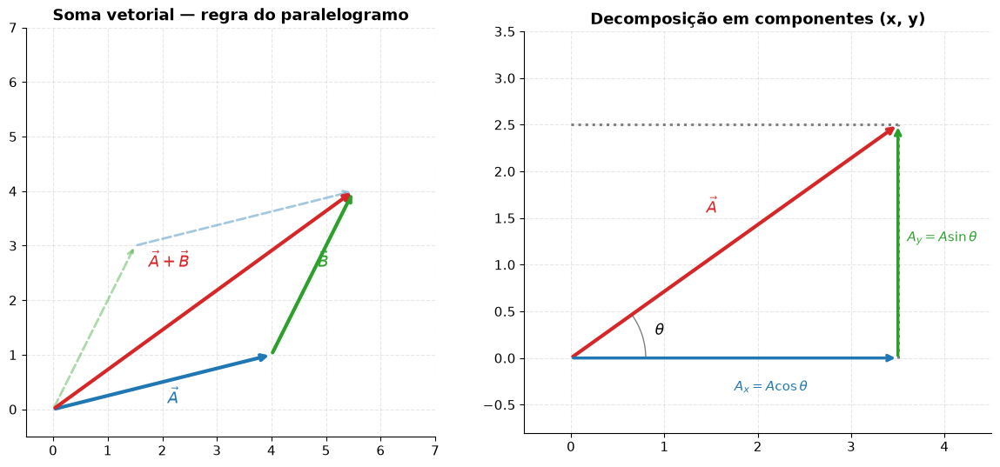

A = [4. 1.], B = [1.5 3. ]
A . B (produto escalar) = 9.00
(A x B)_z (produto vetorial, componente z) = 10.50


In [6]:
A = np.array([4.0, 1.0])
B = np.array([1.5, 3.0])
Soma = A + B

fig, axs = plt.subplots(1, 2, figsize=(12, 5.5))

# --- Soma vetorial pelo paralelogramo ---
ax = axs[0]
origem = np.array([0, 0])
ax.annotate("", xy=A, xytext=origem, arrowprops=dict(arrowstyle="->", color=COR_AZUL, lw=3))
ax.annotate("", xy=Soma, xytext=A, arrowprops=dict(arrowstyle="->", color=COR_OK, lw=3))
ax.annotate("", xy=B, xytext=origem, arrowprops=dict(arrowstyle="->", color=COR_OK, lw=2, alpha=0.4, ls="--"))
ax.annotate("", xy=Soma, xytext=B, arrowprops=dict(arrowstyle="->", color=COR_AZUL, lw=2, alpha=0.4, ls="--"))
ax.annotate("", xy=Soma, xytext=origem, arrowprops=dict(arrowstyle="->", color=COR_DESTAQUE, lw=3))
ax.text(*(A/2 + [0.1, -0.4]), r"$\vec A$", color=COR_AZUL, fontsize=13)
ax.text(*(A + B/2 + [0.1, 0.1]), r"$\vec B$", color=COR_OK, fontsize=13)
ax.text(*(Soma/2 + [-1.0, 0.6]), r"$\vec A+\vec B$", color=COR_DESTAQUE, fontsize=13)
lim = max(Soma.max(), A.max(), B.max()) + 1.5
ax.set_xlim(-0.5, lim); ax.set_ylim(-0.5, lim)
ax.set_aspect("equal")
ax.set_title("Soma vetorial — regra do paralelogramo")

# --- Decomposição em componentes ---
ax = axs[1]
V = np.array([3.5, 2.5])
ax.annotate("", xy=V, xytext=origem, arrowprops=dict(arrowstyle="->", color=COR_DESTAQUE, lw=3))
ax.annotate("", xy=[V[0], 0], xytext=origem, arrowprops=dict(arrowstyle="->", color=COR_AZUL, lw=2.5))
ax.annotate("", xy=V, xytext=[V[0], 0], arrowprops=dict(arrowstyle="->", color=COR_OK, lw=2.5))
ax.plot([V[0], V[0]], [0, V[1]], ":", color="gray")
ax.plot([0, V[0]], [V[1], V[1]], ":", color="gray")
theta = np.degrees(np.arctan2(V[1], V[0]))
arc = Arc((0,0), 1.6, 1.6, angle=0, theta1=0, theta2=theta, color="gray")
ax.add_patch(arc)
ax.text(0.9, 0.25, r"$\theta$", fontsize=12)
ax.text(V[0]/2, -0.35, r"$A_x = A\cos\theta$", color=COR_AZUL, fontsize=11)
ax.text(V[0]+0.1, V[1]/2, r"$A_y = A\sin\theta$", color=COR_OK, fontsize=11)
ax.text(V[0]/2-0.3, V[1]/2+0.3, r"$\vec A$", color=COR_DESTAQUE, fontsize=13)
ax.set_xlim(-0.5, 4.5); ax.set_ylim(-0.8, 3.5)
ax.set_aspect("equal")
ax.set_title("Decomposição em componentes (x, y)")

plt.tight_layout()
plt.show()

produto_escalar = A @ B
produto_vetorial_z = A[0]*B[1] - A[1]*B[0]
print(f"A = {A}, B = {B}")
print(f"A . B (produto escalar) = {produto_escalar:.2f}")
print(f"(A x B)_z (produto vetorial, componente z) = {produto_vetorial_z:.2f}")


> **Dica de prova:** o produto escalar é **máximo** quando os vetores são paralelos ($\theta=0$) e **zero** quando são perpendiculares. Já o produto vetorial é **zero** quando são paralelos e **máximo** quando são perpendiculares — são "opostos" nesse sentido.

<a id="sec2-2"></a>
### 2.2 Lançamento de projéteis

Sem resistência do ar, o movimento em $x$ e em $y$ são **independentes**:

$$x(t) = x_0 + v_0\cos\theta\; t \qquad\qquad y(t) = y_0 + v_0\sin\theta\; t - \tfrac12 g t^2$$

Daí seguem o tempo de voo, a altura máxima e o alcance:

$$t_{voo} = \frac{2v_0\sin\theta}{g} \qquad\qquad H = \frac{v_0^2\sin^2\theta}{2g} \qquad\qquad R = \frac{v_0^2\sin(2\theta)}{g}$$

A fórmula do alcance mostra que $R$ é máximo quando $\sin(2\theta)=1$, ou seja, $\theta = 45°$.

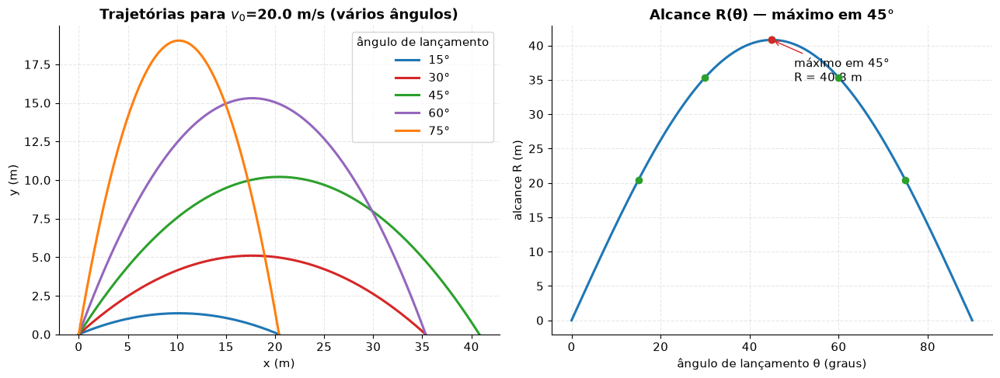

In [7]:
g = 9.8
v0_proj = 20.0
angulos_graus = [15, 30, 45, 60, 75]

fig, axs = plt.subplots(1, 2, figsize=(13, 5))

ax = axs[0]
for ang in angulos_graus:
    th = np.radians(ang)
    t_voo = 2*v0_proj*np.sin(th)/g
    tt = np.linspace(0, t_voo, 200)
    xx = v0_proj*np.cos(th)*tt
    yy = v0_proj*np.sin(th)*tt - 0.5*g*tt**2
    ax.plot(xx, yy, label=f"{ang}°")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax.set_title(f"Trajetórias para $v_0$={v0_proj} m/s (vários ângulos)")
ax.legend(title="ângulo de lançamento")
ax.set_ylim(bottom=0)

ax = axs[1]
th_cont = np.linspace(0, 90, 300)
R_cont = v0_proj**2 * np.sin(2*np.radians(th_cont)) / g
ax.plot(th_cont, R_cont, color=COR_AZUL)
R_45 = v0_proj**2/g
ax.scatter([45], [R_45], color=COR_DESTAQUE, zorder=5)
ax.annotate(f"máximo em 45°\nR = {R_45:.1f} m", xy=(45, R_45),
            xytext=(50, R_45-6), arrowprops=dict(arrowstyle="->", color=COR_DESTAQUE))
for ang in angulos_graus:
    th = np.radians(ang)
    R = v0_proj**2*np.sin(2*th)/g
    ax.scatter([ang], [R], color=COR_OK, zorder=4)
ax.set_xlabel("ângulo de lançamento θ (graus)")
ax.set_ylabel("alcance R (m)")
ax.set_title("Alcance R(θ) — máximo em 45°")

plt.tight_layout()
plt.show()


Agora a animação: um projétil lançado a 45°, com os vetores de velocidade (e suas componentes $v_x$, $v_y$) se atualizando ao longo do voo. Note que $v_x$ é sempre constante e $v_y$ diminui, zera no topo e volta a crescer (em módulo) na descida.

In [8]:
theta_anim = np.radians(45)
t_voo = 2*v0_proj*np.sin(theta_anim)/g
n_frames = 50
tt = np.linspace(0, t_voo, n_frames)
xx = v0_proj*np.cos(theta_anim)*tt
yy = v0_proj*np.sin(theta_anim)*tt - 0.5*g*tt**2
vxx = np.full_like(tt, v0_proj*np.cos(theta_anim))
vyy = v0_proj*np.sin(theta_anim) - g*tt

fig, ax = plt.subplots(figsize=(8,5))
ax.plot(xx, yy, "--", color="lightgray", lw=1.5, zorder=1)
ax.set_xlim(-2, xx.max()+5)
ax.set_ylim(-1, yy.max()+5)
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax.set_title("Lançamento de projétil (θ=45°) — vetor velocidade e componentes")

ponto, = ax.plot([], [], "o", color=COR_DESTAQUE, markersize=12, zorder=5)
seta_v = ax.annotate("", xy=(0,0), xytext=(0,0), arrowprops=dict(arrowstyle="->", color="black", lw=2.2))
seta_vx = ax.annotate("", xy=(0,0), xytext=(0,0), arrowprops=dict(arrowstyle="->", color=COR_AZUL, lw=2))
seta_vy = ax.annotate("", xy=(0,0), xytext=(0,0), arrowprops=dict(arrowstyle="->", color=COR_OK, lw=2))

escala = 0.35

def init2():
    ponto.set_data([], [])
    return ponto,

def update2(i):
    px, py = xx[i], yy[i]
    ponto.set_data([px], [py])
    seta_v.set_position((px, py)); seta_v.xy = (px+escala*vxx[i], py+escala*vyy[i])
    seta_vx.set_position((px, py)); seta_vx.xy = (px+escala*vxx[i], py)
    seta_vy.set_position((px, py)); seta_vy.xy = (px, py+escala*vyy[i])
    return ponto, seta_v, seta_vx, seta_vy

anim2 = animation.FuncAnimation(fig, update2, frames=n_frames, init_func=init2,
                                 interval=70, blit=False)
plt.close(fig)
HTML(anim2.to_jshtml())


> **Intuição física:** é por isso que a trajetória do projétil é uma parábola — $x(t)$ é linear em $t$ e $y(t)$ é quadrática em $t$; eliminando $t$ de uma equação na outra, sobra $y$ como função quadrática de $x$.

<a id="sec2-3"></a>
### 2.3 Movimento circular uniforme (MCU)

Na trajetória circular de raio $r$ com velocidade angular constante $\omega$, a velocidade tangencial tem módulo

$$v = \omega r$$

e aponta **tangente** à trajetória. Mesmo com $|\vec v|$ constante, a *direção* de $\vec v$ muda — logo há aceleração, chamada **aceleração centrípeta**, que aponta sempre para o centro:

$$a_c = \frac{v^2}{r} = \omega^2 r$$

In [9]:
r_mcu = 3.0
omega = 1.3
n_frames = 72
tt = np.linspace(0, 2*np.pi/omega, n_frames)
xx = r_mcu*np.cos(omega*tt)
yy = r_mcu*np.sin(omega*tt)
vxx = -r_mcu*omega*np.sin(omega*tt)
vyy = r_mcu*omega*np.cos(omega*tt)
ac = omega**2*r_mcu

fig, ax = plt.subplots(figsize=(6,6))
theta_c = np.linspace(0, 2*np.pi, 200)
ax.plot(r_mcu*np.cos(theta_c), r_mcu*np.sin(theta_c), "--", color="lightgray")
ax.scatter([0], [0], color="black", s=30, zorder=5)
ax.set_xlim(-r_mcu-2.5, r_mcu+2.5); ax.set_ylim(-r_mcu-2.5, r_mcu+2.5)
ax.set_aspect("equal")
ax.set_title(f"MCU: v = ωr = {omega*r_mcu:.2f} m/s,  a_c = ω²r = {ac:.2f} m/s²")

ponto, = ax.plot([], [], "o", color=COR_DESTAQUE, markersize=12, zorder=6)
seta_v = ax.annotate("", xy=(0,0), xytext=(0,0), arrowprops=dict(arrowstyle="->", color=COR_AZUL, lw=2.5))
seta_a = ax.annotate("", xy=(0,0), xytext=(0,0), arrowprops=dict(arrowstyle="->", color=COR_DESTAQUE, lw=2.5))

escala_v = 0.5
escala_a = 0.9

def init3():
    ponto.set_data([], [])
    return ponto,

def update3(i):
    px, py = xx[i], yy[i]
    ponto.set_data([px], [py])
    seta_v.set_position((px, py)); seta_v.xy = (px+escala_v*vxx[i], py+escala_v*vyy[i])
    # aceleração centrípeta aponta para o centro: direção (-px,-py) normalizada
    ax_dir, ay_dir = -px/r_mcu, -py/r_mcu
    seta_a.set_position((px, py)); seta_a.xy = (px+escala_a*ax_dir, py+escala_a*ay_dir)
    return ponto, seta_v, seta_a

anim3 = animation.FuncAnimation(fig, update3, frames=n_frames, init_func=init3,
                                 interval=55, blit=False)
plt.close(fig)
HTML(anim3.to_jshtml())


> **Dica de prova:** vetor velocidade (azul) é sempre **tangente** à trajetória; vetor aceleração centrípeta (vermelho) é sempre **perpendicular** à velocidade e aponta para o centro — os dois vetores giram junto com a partícula, mas mantêm esse ângulo de 90° entre si o tempo todo.

<a id="sec3"></a>
## 3. Leis de Newton

<a id="sec3-1"></a>
### 3.1 As três leis

**1ª Lei (Inércia):** um corpo permanece em repouso ou em MRU a menos que uma força resultante externa atue sobre ele.
$$\sum \vec F = 0 \iff \vec a = 0$$

**2ª Lei (Lei Fundamental da Dinâmica):** a força resultante produz aceleração proporcional à massa:
$$\sum \vec F = m\vec a$$

**3ª Lei (Ação e Reação):** se o corpo A exerce uma força $\vec F_{A\to B}$ sobre B, então B exerce sobre A uma força de mesma intensidade e direção oposta:
$$\vec F_{A\to B} = -\vec F_{B\to A}$$

<a id="sec3-2"></a>
### 3.2 Ação e reação

Um ponto que confunde muitos alunos: as forças de um par ação-reação atuam em **corpos diferentes**, então elas nunca se cancelam entre si (cancelamento só ocorre entre forças no *mesmo* corpo). Vejamos dois exemplos clássicos lado a lado.

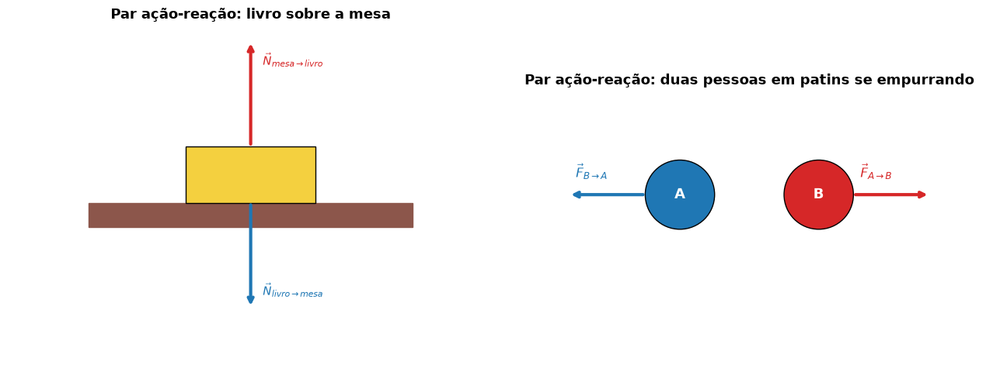

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))

# --- Exemplo 1: livro sobre a mesa ---
ax = axs[0]
ax.add_patch(plt.Rectangle((-2, -0.3), 4, 0.3, color="#8c564b"))  # mesa
ax.add_patch(plt.Rectangle((-0.8, 0), 1.6, 0.7, color="#f4d03f", ec="black"))  # livro
cx, cy_top, cy_bot = 0, 0.7, 0
ax.annotate("", xy=(cx, cy_top+1.3), xytext=(cx, cy_top),
            arrowprops=dict(arrowstyle="->", color=COR_DESTAQUE, lw=3))
ax.text(cx+0.15, cy_top+1.0, r"$\vec N_{mesa \to livro}$", color=COR_DESTAQUE, fontsize=11)
ax.annotate("", xy=(cx, cy_bot-1.3), xytext=(cx, cy_bot),
            arrowprops=dict(arrowstyle="->", color=COR_AZUL, lw=3))
ax.text(cx+0.15, cy_bot-1.15, r"$\vec N_{livro \to mesa}$", color=COR_AZUL, fontsize=11)
ax.set_xlim(-3, 3); ax.set_ylim(-2, 2.2)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Par ação-reação: livro sobre a mesa")

# --- Exemplo 2: duas pessoas em patins se empurrando ---
ax = axs[1]
p1, p2 = -1.0, 1.0
ax.add_patch(Circle((p1, 0), 0.5, color="#1f77b4", ec="black"))
ax.add_patch(Circle((p2, 0), 0.5, color="#d62728", ec="black"))
ax.text(p1, 0, "A", ha="center", va="center", color="white", fontweight="bold", fontsize=13)
ax.text(p2, 0, "B", ha="center", va="center", color="white", fontweight="bold", fontsize=13)
ax.annotate("", xy=(p1-1.6, 0.0), xytext=(p1-0.5, 0.0),
            arrowprops=dict(arrowstyle="->", color=COR_AZUL, lw=3))
ax.text(p1-1.5, 0.25, r"$\vec F_{B\to A}$", color=COR_AZUL, fontsize=12)
ax.annotate("", xy=(p2+1.6, 0.0), xytext=(p2+0.5, 0.0),
            arrowprops=dict(arrowstyle="->", color=COR_DESTAQUE, lw=3))
ax.text(p2+0.6, 0.25, r"$\vec F_{A\to B}$", color=COR_DESTAQUE, fontsize=12)
ax.set_xlim(-3.5, 3.5); ax.set_ylim(-1.5, 1.5)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Par ação-reação: duas pessoas em patins se empurrando")

plt.tight_layout()
plt.show()


> **Intuição física:** no exemplo do livro, $\vec N_{mesa\to livro}$ atua *no livro*, e $\vec N_{livro\to mesa}$ atua *na mesa* — elas têm mesma intensidade, mas não se cancelam porque estão em corpos diferentes. O que mantém o livro em equilíbrio é o cancelamento entre $\vec N_{mesa\to livro}$ e o peso do próprio livro (duas forças *nele*, não um par ação-reação).

<a id="sec3-3"></a>
### 3.3 Atrito estático e cinético

Quando tentamos mover um bloco apoiado sobre uma superfície, a força de atrito **estático** reage igualando a força aplicada, até um limite máximo:

$$f_e \le \mu_s N$$

Quando o bloco começa a deslizar, o atrito passa a ser **cinético**, com valor aproximadamente constante:

$$f_c = \mu_k N \qquad (\mu_k < \mu_s \text{ em geral})$$

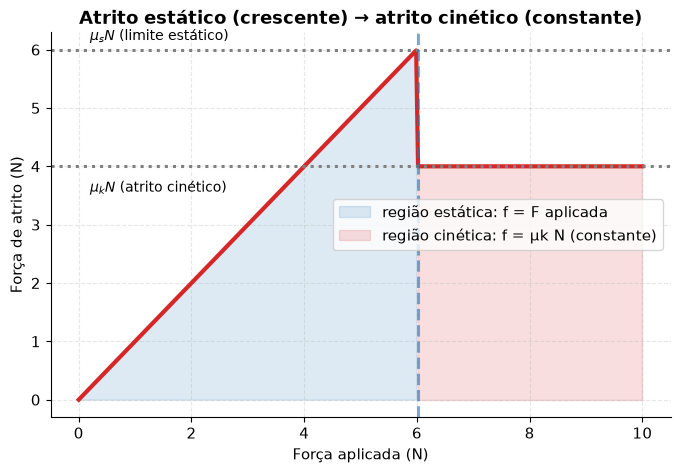

In [11]:
mu_s, mu_k = 0.6, 0.4
N_normal = 10.0  # N

F_aplicada = np.linspace(0, 10, 300)
f_atrito = np.where(F_aplicada <= mu_s*N_normal, F_aplicada, mu_k*N_normal)

fig, ax = plt.subplots()
ax.plot(F_aplicada, f_atrito, color=COR_DESTAQUE, lw=3)
ax.axhline(mu_s*N_normal, color="gray", ls=":")
ax.axhline(mu_k*N_normal, color="gray", ls=":")
ax.text(0.2, mu_s*N_normal+0.15, r"$\mu_s N$ (limite estático)", fontsize=10)
ax.text(0.2, mu_k*N_normal-0.45, r"$\mu_k N$ (atrito cinético)", fontsize=10)
idx_limite = np.argmax(F_aplicada > mu_s*N_normal)
ax.axvline(F_aplicada[idx_limite], color=COR_AZUL, ls="--", alpha=0.6)
ax.fill_between(F_aplicada[:idx_limite], f_atrito[:idx_limite], alpha=0.15, color=COR_AZUL,
                 label="região estática: f = F aplicada")
ax.fill_between(F_aplicada[idx_limite:], f_atrito[idx_limite:], alpha=0.15, color=COR_DESTAQUE,
                 label="região cinética: f = μk N (constante)")
ax.set_xlabel("Força aplicada (N)")
ax.set_ylabel("Força de atrito (N)")
ax.set_title("Atrito estático (crescente) → atrito cinético (constante)")
ax.legend()
plt.show()


Agora, um bloco em um plano inclinado: variamos o ângulo $\theta$ e comparamos $\tan\theta$ (razão entre a componente do peso que "puxa" o bloco para baixo e a componente normal) com $\mu_s$. O bloco começa a deslizar quando $\tan\theta > \mu_s$.

In [12]:
mu_s_plano = 0.5
angulo_critico = np.degrees(np.arctan(mu_s_plano))

n_frames = 60
angulos = np.linspace(2, 50, n_frames)

fig, (ax_plano, ax_graf) = plt.subplots(1, 2, figsize=(13, 5.5))

L = 4.0
ax_plano.set_xlim(-1, 5); ax_plano.set_ylim(-1, 4)
ax_plano.set_aspect("equal"); ax_plano.axis("off")
ax_plano.set_title("Bloco em plano inclinado")

ax_graf.plot(angulos, np.tan(np.radians(angulos)), color=COR_AZUL, label=r"$\tan\theta$")
ax_graf.axhline(mu_s_plano, color=COR_DESTAQUE, ls="--", label=r"$\mu_s$")
ax_graf.axvline(angulo_critico, color="gray", ls=":")
ax_graf.annotate(f"θ_crítico ≈ {angulo_critico:.1f}°", xy=(angulo_critico, mu_s_plano),
                  xytext=(angulo_critico+3, mu_s_plano+0.4),
                  arrowprops=dict(arrowstyle="->", color="gray"))
ax_graf.set_xlabel("ângulo de inclinação θ (graus)")
ax_graf.set_ylabel("valor")
ax_graf.set_title("Início do deslizamento: tanθ = μs")
ax_graf.legend()
ax_graf.set_ylim(0, 2)
marcador_graf, = ax_graf.plot([], [], "o", color=COR_OK, markersize=10, zorder=5)

def desenha_plano(theta_graus):
    ax_plano.clear()
    ax_plano.set_xlim(-1, 5); ax_plano.set_ylim(-1, 4)
    ax_plano.set_aspect("equal"); ax_plano.axis("off")
    th = np.radians(theta_graus)
    base = np.array([0, 0]); topo = np.array([L*np.cos(th), L*np.sin(th)])
    chao = np.array([L*np.cos(th), 0])
    ax_plano.plot([base[0], topo[0]], [base[1], topo[1]], color="black", lw=3)
    ax_plano.plot([base[0], chao[0]], [base[1], chao[1]], color="black", lw=3)
    deslizou = np.tan(th) > mu_s_plano
    frac = 0.35 if not deslizou else 0.35 + 0.4*min((theta_graus-angulo_critico)/20, 1)
    pos = base + frac*(topo-base)
    normal_dir = np.array([-np.sin(th), np.cos(th)])
    bloco_centro = pos + 0.18*normal_dir
    cor_bloco = COR_OK if not deslizou else COR_DESTAQUE
    ax_plano.add_patch(plt.Rectangle(bloco_centro-0.2, 0.4, 0.3, angle=theta_graus,
                                      color=cor_bloco, ec="black", zorder=5))
    estado = "EM REPOUSO (atrito estático segura)" if not deslizou else "DESLIZANDO (venceu o atrito estático!)"
    ax_plano.set_title(f"θ = {theta_graus:.1f}°  —  {estado}")
    return deslizou

def init4():
    marcador_graf.set_data([], [])
    return marcador_graf,

def update4(i):
    th_g = angulos[i]
    desenha_plano(th_g)
    marcador_graf.set_data([th_g], [np.tan(np.radians(th_g))])
    return marcador_graf,

anim4 = animation.FuncAnimation(fig, update4, frames=n_frames, init_func=init4,
                                 interval=90, blit=False)
plt.close(fig)
HTML(anim4.to_jshtml())


> **Dica de prova:** o ângulo crítico de um plano inclinado é simplesmente $\theta_c = \arctan(\mu_s)$. Esse é um jeito rápido de "medir" $\mu_s$ experimentalmente: basta inclinar a superfície até o bloco começar a escorregar.

<a id="sec3-4"></a>
### 3.4 Dinâmica do movimento circular

Pela 2ª Lei de Newton aplicada à direção radial, a força resultante centrípeta é

$$F_c = \frac{mv^2}{r} = m\omega^2 r$$

Essa força não é um "novo tipo" de força — é a *resultante* das forças reais (tração, normal, atrito, peso) na direção radial. Dois exemplos clássicos:

**Pêndulo cônico:** uma massa presa por um fio gira em um círculo horizontal, com o fio inclinado de um ângulo $\theta$ em relação à vertical. Decompondo a tração $\vec T$:
$$T\cos\theta = mg \qquad\qquad T\sin\theta = \frac{mv^2}{r}$$

**Curva com atrito (pista plana):** o atrito estático entre os pneus e a pista fornece a força centrípeta. A velocidade máxima sem derrapar satisfaz
$$\mu_s m g = \frac{mv_{max}^2}{r} \;\Longrightarrow\; v_{max} = \sqrt{\mu_s g r}$$

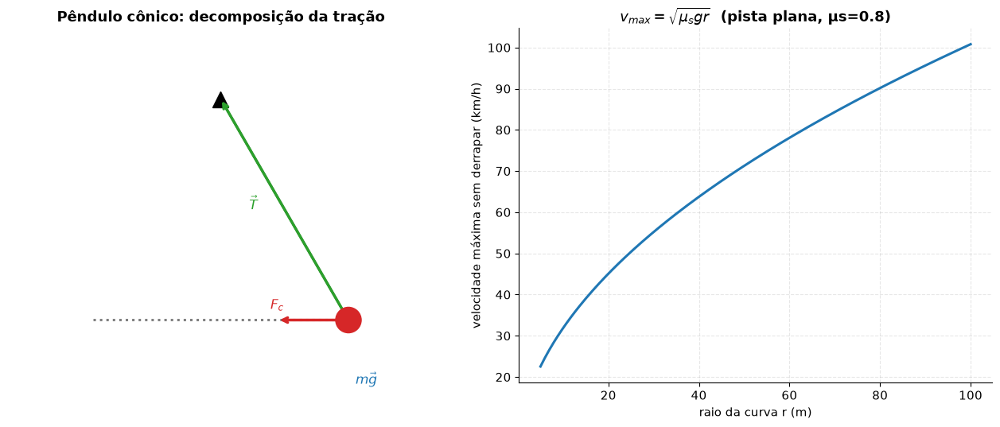

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))

# --- Pêndulo cônico ---
ax = axs[0]
theta_pend = np.radians(30)
topo = np.array([0, 3])
r_pend = 1.8*np.sin(theta_pend)*2
massa = topo + np.array([r_pend, -1.8*np.cos(theta_pend)*2])
ax.plot([topo[0]], [topo[1]], "^", color="black", markersize=14)
ax.plot([topo[0], massa[0]], [topo[1], massa[1]], color="black", lw=2)
ax.add_patch(Circle(massa, 0.18, color=COR_DESTAQUE, zorder=5))
ax.plot([topo[0]-r_pend, topo[0]+r_pend], [massa[1], massa[1]], ":", color="gray")
# forças na massa
ax.annotate("", xy=(massa[0], massa[1]-1.0), xytext=(massa[0], massa[1]),
            arrowprops=dict(arrowstyle="->", color=COR_AZUL, lw=2.5))
ax.text(massa[0]+0.1, massa[1]-0.9, "$m\\vec g$", color=COR_AZUL, fontsize=12)
ax.annotate("", xy=topo, xytext=massa,
            arrowprops=dict(arrowstyle="->", color=COR_OK, lw=2.5))
ax.text((topo[0]+massa[0])/2-0.5, (topo[1]+massa[1])/2, "$\\vec T$", color=COR_OK, fontsize=12)
ax.annotate("", xy=(massa[0]-1.0, massa[1]), xytext=(massa[0], massa[1]),
            arrowprops=dict(arrowstyle="->", color=COR_DESTAQUE, lw=2.5))
ax.text(massa[0]-1.1, massa[1]+0.15, "$F_c$", color=COR_DESTAQUE, fontsize=12)
ax.set_xlim(-3, 3); ax.set_ylim(-1, 4)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Pêndulo cônico: decomposição da tração")

# --- Curva com atrito: v_max vs raio ---
ax = axs[1]
mu_s_curva = 0.8
g_curva = 9.8
raios = np.linspace(5, 100, 200)
v_max = np.sqrt(mu_s_curva*g_curva*raios)
ax.plot(raios, v_max*3.6, color=COR_AZUL)  # convertendo para km/h
ax.set_xlabel("raio da curva r (m)")
ax.set_ylabel("velocidade máxima sem derrapar (km/h)")
ax.set_title(r"$v_{max}=\sqrt{\mu_s g r}$  (pista plana, μs=0.8)")

plt.tight_layout()
plt.show()


> **Intuição física:** note que $v_{max}$ cresce apenas com a **raiz quadrada** do raio — dobrar o raio da curva não dobra a velocidade segura, aumenta por um fator de $\sqrt{2}\approx 1,41$. É por isso que curvas fechadas (raio pequeno) exigem reduções de velocidade desproporcionalmente grandes.

---

## Resumo rápido

| Tópico | Fórmula-chave |
|---|---|
| Velocidade/aceleração | $v=dx/dt,\; a=dv/dt$ |
| MRUV | $x=x_0+v_0t+\tfrac12at^2,\; v=v_0+at,\; v^2=v_0^2+2a\Delta x$ |
| Deslocamento | $\Delta x = \int v\,dt$ = área sob $v(t)$ |
| Projétil | $x=v_0\cos\theta\,t,\;\; y=v_0\sin\theta\,t-\tfrac12gt^2,\;\; R=\dfrac{v_0^2\sin2\theta}{g}$ |
| MCU | $v=\omega r,\;\; a_c=v^2/r=\omega^2 r$ |
| Newton | $\sum\vec F=m\vec a,\;\; \vec F_{A\to B}=-\vec F_{B\to A}$ |
| Atrito | $f_e\le\mu_sN,\;\; f_c=\mu_kN$ |
| Força centrípeta | $F_c=mv^2/r$ |

Bons estudos!
